In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv('pedidos_taller.csv')

In [4]:
print('Primeras filas:')
print(data.head(3))
print('\nFilas y columnas:', data.shape)

Primeras filas:
   numero_cliente tipo_cliente  canal_venta categoria_producto dia_semana  \
0               0   consumidor  loja_fisica          vestuário    segunda   
1               1   consumidor   revendedor         escritório     quarta   
2               2      empresa       online          alimentos      sexta   

  promocion  tiempo_entrega_previsto  num_productos localizacion    x    y  
0       sim                        4             30    (0, -640)    0 -640  
1       não                        2              7  (912, -400)  912 -400  
2       não                        2              3  (570, -160)  570 -160  

Filas y columnas: (100, 11)


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   numero_cliente           100 non-null    int64 
 1   tipo_cliente             100 non-null    object
 2   canal_venta              100 non-null    object
 3   categoria_producto       100 non-null    object
 4   dia_semana               100 non-null    object
 5   promocion                100 non-null    object
 6   tiempo_entrega_previsto  100 non-null    int64 
 7   num_productos            100 non-null    int64 
 8   localizacion             100 non-null    object
 9   x                        100 non-null    int64 
 10  y                        100 non-null    int64 
dtypes: int64(5), object(6)
memory usage: 8.7+ KB


In [6]:
print('\nValores nulos por columna:')
print(data.isnull().sum())
print('\nFilas duplicadas:', data.duplicated().sum())

print('\nResumen de productos y tiempo de entrega:')
print(data[['num_productos', 'tiempo_entrega_previsto']].describe().round(2))


Valores nulos por columna:
numero_cliente             0
tipo_cliente               0
canal_venta                0
categoria_producto         0
dia_semana                 0
promocion                  0
tiempo_entrega_previsto    0
num_productos              0
localizacion               0
x                          0
y                          0
dtype: int64

Filas duplicadas: 0

Resumen de productos y tiempo de entrega:
       num_productos  tiempo_entrega_previsto
count         100.00                   100.00
mean           14.31                     2.90
std            18.79                     1.49
min             0.00                     1.00
25%             2.00                     1.75
50%             7.00                     3.00
75%            21.25                     4.00
max           111.00                     5.00


**EJERCICIO 1**


1. Cantidad de productos por categoría y promoción:
promocion            si   no
categoria_producto          
alimentos           241  125
eletrônico          219   87
escritório          379  121
vestuário           215   44


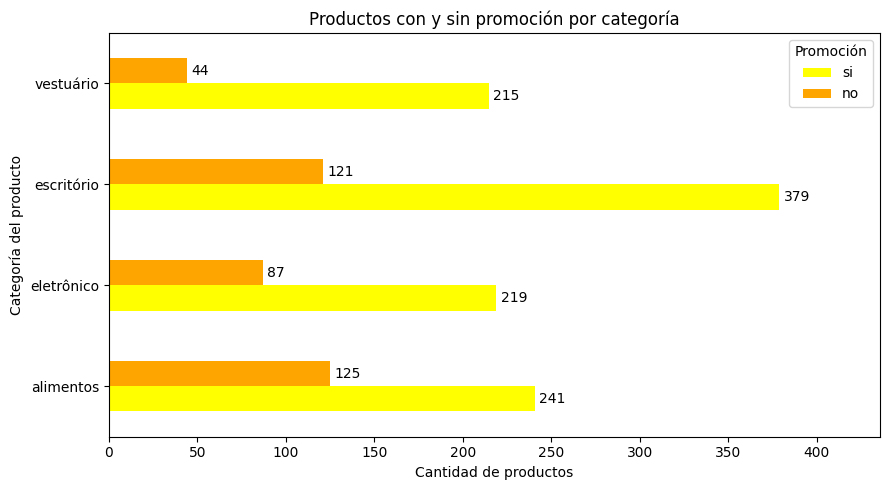

In [18]:
data['promocion'] = data['promocion'].replace({
    'Sim': 'si',
    'sim': 'si',
    'nÃ£o': 'no',
    'não': 'no'
})

tabla_productos = data.pivot_table(
    values='num_productos',
    index='categoria_producto',
    columns='promocion',
    aggfunc='sum'
)
tabla_productos = tabla_productos[['si', 'no']]

print('\n1. Cantidad de productos por categoría y promoción:')
print(tabla_productos)

# ADICIONAL: barh dibuja barras horizontales.
grafico = tabla_productos.plot(
    kind='barh',
    figsize=(9, 5),
    color=['yellow', 'orange']
)

# ADICIONAL: bar_label escribe la cantidad al final de cada barra.
for barras in grafico.containers:
    grafico.bar_label(barras, fmt='%.0f', padding=3)

grafico.margins(x=0.15)
grafico.set_title('Productos con y sin promoción por categoría')
grafico.set_xlabel('Cantidad de productos')
grafico.set_ylabel('Categoría del producto')
grafico.legend(title='Promoción')
plt.tight_layout()
plt.show()

**EJERCICIO 2**

In [8]:
data['canal_venta'] = data['canal_venta'].replace({
    'loja_fisica': 'tienda_fisica',
    'revendedor': 'distribuidor',
    'online': 'online'
})

pedidos_por_canal = data['canal_venta'].value_counts()
total_pedidos = pedidos_por_canal.sum()

print('\n2. Cantidad de pedidos por canal de venta:')
print(pedidos_por_canal)


2. Cantidad de pedidos por canal de venta:
canal_venta
online           52
tienda_fisica    25
distribuidor     23
Name: count, dtype: int64


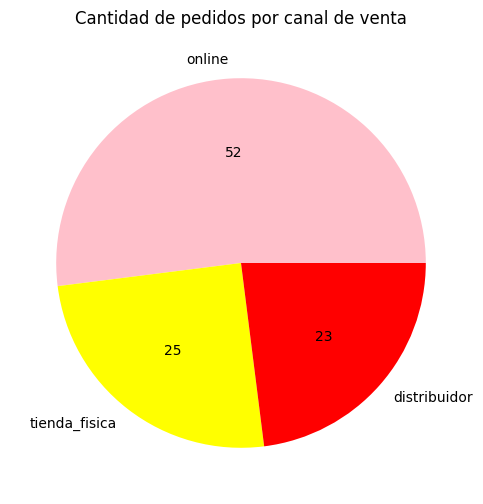

In [17]:
pedidos_por_canal.plot.pie(
    figsize=(6, 6),
    colors=['pink','yellow','red'],
    autopct=lambda porcentaje: f'{porcentaje * total_pedidos / 100:.0f}'
)
plt.title('Cantidad de pedidos por canal de venta')
plt.ylabel('')
plt.show()

**EJERCICIO 3**

In [9]:
data['dia_semana'] = data['dia_semana'].replace({
    'segunda': 'lunes',
    'terça': 'martes',
    'quarta': 'miércoles',
    'quinta': 'jueves',
    'sexta': 'viernes',
    'sábado': 'sábado',
    'domingo': 'domingo'
})

dias = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo']

promedio_dia = data.groupby('dia_semana')['num_productos'].mean()

In [10]:
promedio_dia = promedio_dia.reindex(dias).dropna()
suma_promedios = promedio_dia.sum()

print('\n3. Promedio de productos por pedido y día:')
print(promedio_dia.round(2))


3. Promedio de productos por pedido y día:
dia_semana
lunes        19.23
martes       20.06
miércoles    16.30
jueves        9.57
viernes       9.52
Name: num_productos, dtype: float64


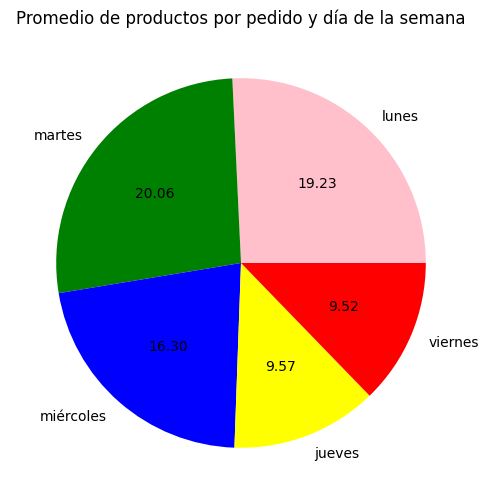

In [16]:
promedio_dia.plot.pie(
    figsize=(6, 6),
    colors=['pink', 'green', 'blue','yellow','red'],
    autopct=lambda porcentaje: f'{porcentaje * suma_promedios / 100:.2f}'
)
plt.title('Promedio de productos por pedido y día de la semana')
plt.ylabel('')
plt.show()

**EJERCICIO 4**

In [13]:
data['urgencia'] = pd.cut(
    data['tiempo_entrega_previsto'],
    bins=[0, 2, 3, 5],
    labels=['Alta', 'Media', 'Baja']
)

tabla_urgencia = pd.crosstab(
    index=data['tipo_cliente'],
    columns=data['urgencia']
)

print('\n4. Cantidad de pedidos por tipo de cliente y urgencia:')
print(tabla_urgencia)


4. Cantidad de pedidos por tipo de cliente y urgencia:
urgencia      Alta  Media  Baja
tipo_cliente                   
consumidor      17     10    23
empresa         27      8    15


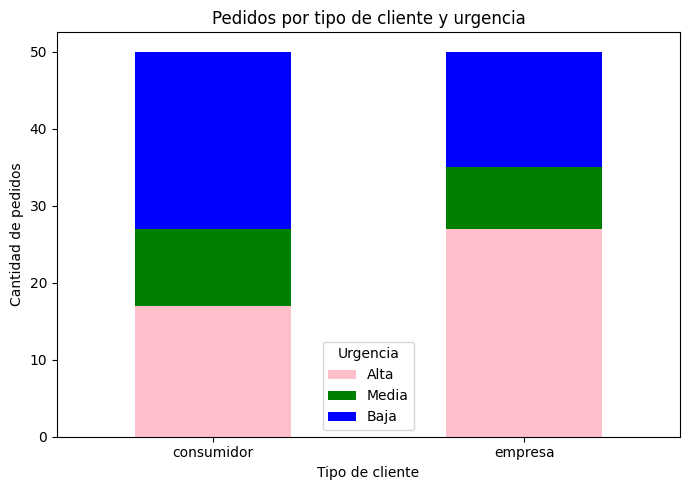

In [15]:
grafico = tabla_urgencia.plot(
    kind='bar',
    stacked=True,
    figsize=(7, 5),
    color=['pink', 'green', 'blue'],
    rot=0
)
grafico.set_title('Pedidos por tipo de cliente y urgencia')
grafico.set_xlabel('Tipo de cliente')
grafico.set_ylabel('Cantidad de pedidos')
grafico.legend(title='Urgencia')
plt.tight_layout()
plt.show()